# Experiment: Predicting Fuel Efficiency (mpg) with Linear Regression
Follows the plan in `methodology.md`. Research question: how accurately can a linear model predict mpg, and does Ridge plus engineered features beat plain OLS on unseen cars?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, RidgeCV, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load and inspect the data

In [2]:
df = pd.read_csv('data/auto_mpg.csv')
print('Shape:', df.shape)
display(df.head())
print(df.dtypes)

Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin              str
name                str
dtype: object


In [3]:
print('Missing values per column:'); print(df.isna().sum()[lambda s: s>0])
print('Duplicate rows:', df.duplicated().sum())
display(df.describe().T.round(2))

Missing values per column:
horsepower    6
dtype: int64
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0


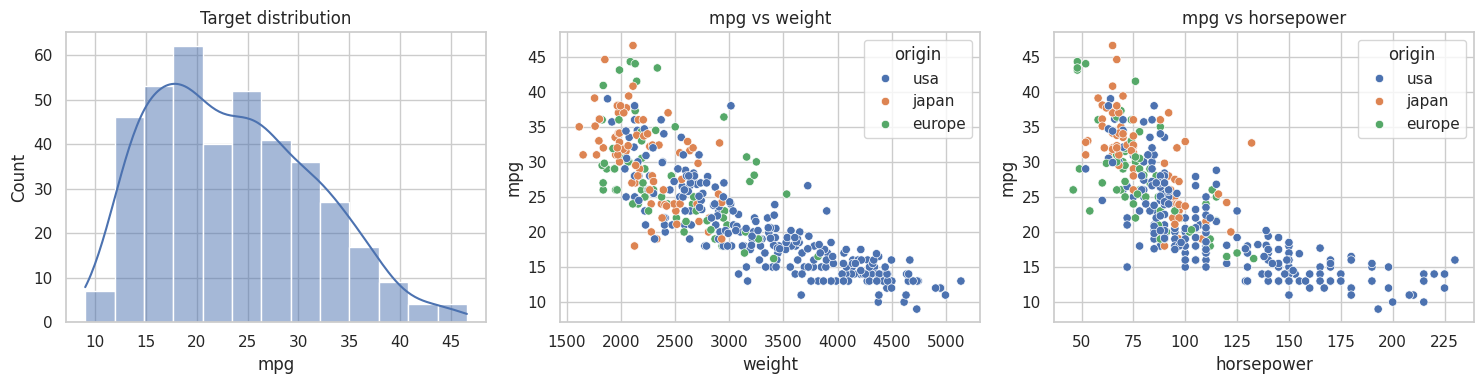

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['mpg'], kde=True, ax=ax[0]); ax[0].set_title('Target distribution')
sns.scatterplot(data=df, x='weight', y='mpg', hue='origin', ax=ax[1]); ax[1].set_title('mpg vs weight')
sns.scatterplot(data=df, x='horsepower', y='mpg', hue='origin', ax=ax[2]); ax[2].set_title('mpg vs horsepower')
plt.tight_layout(); plt.show()

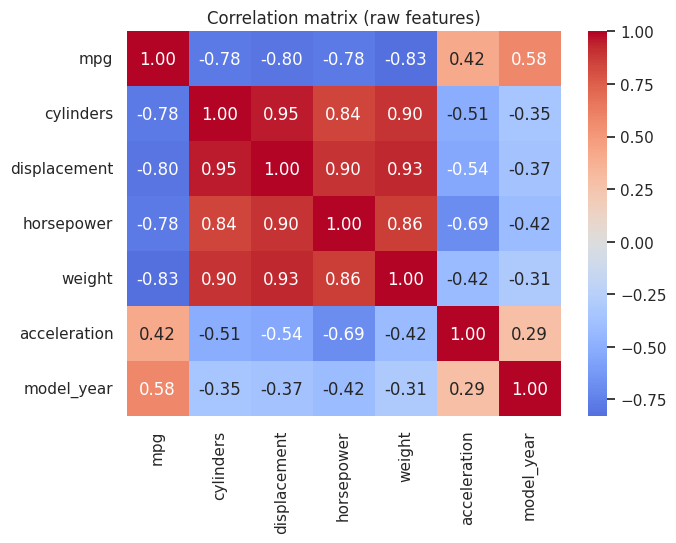

In [5]:
num = df.drop(columns=['name', 'origin'])
plt.figure(figsize=(7, 5)); sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (raw features)'); plt.show()

**Observations:** `mpg` is right-skewed. The mpg-weight and mpg-horsepower relationships are curved (steeper for light cars). Weight, displacement, cylinders and horsepower are all strongly correlated with each other (|r| > 0.8 for several pairs), the multicollinearity issue that motivates Ridge. Only `horsepower` has missing values (6 rows).

## 2. Data cleaning
Plan: sanity-check values, keep real outliers, split 80/20 **before** fitting anything, and impute the 6 missing `horsepower` values with the **training-set median** (inside a pipeline so the test set never leaks in).

In [6]:
assert (df['weight'] > 0).all() and (df['mpg'] > 0).all(), 'impossible values found'
print('Rows with missing horsepower:'); display(df[df['horsepower'].isna()][['mpg','cylinders','displacement','horsepower','weight','name']])
print('Outliers kept (real cars): mpg > 40 ->', (df['mpg'] > 40).sum(), 'rows; weight > 5000 ->', (df['weight'] > 5000).sum(), 'rows')

Rows with missing horsepower:


,mpg,cylinders,displacement,horsepower,weight,name
32,25.0,4,98.0,NaN,2046,ford pinto
126,21.0,6,200.0,NaN,2875,ford maverick
330,40.9,4,85.0,NaN,1835,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,ford mustang cobra
354,34.5,4,100.0,NaN,2320,renault 18i
374,23.0,4,151.0,NaN,3035,amc concord dl


Outliers kept (real cars): mpg > 40 -> 9 rows; weight > 5000 -> 1 rows


In [7]:
X_raw = df.drop(columns=['mpg', 'name'])
y = df['mpg']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train_raw.shape, ' Test:', X_test_raw.shape)
print('Train missing horsepower:', X_train_raw['horsepower'].isna().sum(), ' Test missing horsepower:', X_test_raw['horsepower'].isna().sum())
print('Training median horsepower (used for imputation):', X_train_raw['horsepower'].median())

Train: (318, 7)  Test: (80, 7)
Train missing horsepower: 5  Test missing horsepower: 1
Training median horsepower (used for imputation): 92.0


## 3. Feature engineering
A custom transformer so that imputation is *fit on training data only*, even inside each cross-validation fold. It builds two feature sets:
- **raw**: the original numeric columns plus one-hot `origin` (imputed horsepower)
- **engineered**: raw + `log_weight`, `power_to_weight`, `disp_per_cyl`, `car_age`

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin

class FeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, engineered=True):
        self.engineered = engineered
    def fit(self, X, y=None):
        self.hp_median_ = X['horsepower'].median()      # learned from training data only
        return self
    def transform(self, X):
        X = X.copy()
        X['horsepower'] = X['horsepower'].fillna(self.hp_median_)
        out = X[['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']].copy()
        out['origin_europe'] = (X['origin'] == 'europe').astype(int)   # USA is the baseline
        out['origin_japan'] = (X['origin'] == 'japan').astype(int)
        if self.engineered:
            out['log_weight'] = np.log(X['weight'])
            out['power_to_weight'] = X['horsepower'] / X['weight']
            out['disp_per_cyl'] = X['displacement'] / X['cylinders']
            out['car_age'] = 83 - X['model_year']
        return out

In [9]:
fb_raw = FeatureBuilder(engineered=False).fit(X_train_raw)
fb_eng = FeatureBuilder(engineered=True).fit(X_train_raw)
F_train = fb_eng.transform(X_train_raw)
print('Raw feature count:', fb_raw.transform(X_train_raw).shape[1], '| Engineered feature count:', F_train.shape[1])
print('Missing values after cleaning (train/test):', F_train.isna().sum().sum(), '/', fb_eng.transform(X_test_raw).isna().sum().sum())
display(F_train.head())

Raw feature count: 8 | Engineered feature count: 12
Missing values after cleaning (train/test): 0 / 0


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_europe,origin_japan,log_weight,power_to_weight,disp_per_cyl,car_age
3,8,304.0,150.0,3433,12.0,70,0,0,8.141190,0.043694,38.00,13
18,4,97.0,88.0,2130,14.5,70,0,1,7.663877,0.041315,24.25,13
376,4,91.0,68.0,2025,18.2,82,0,1,7.613325,0.033580,22.75,1
248,4,91.0,60.0,1800,16.4,78,0,1,7.495542,0.033333,22.75,5
177,4,115.0,95.0,2694,15.0,75,1,0,7.898782,0.035264,28.75,8


Correlation of each feature with mpg (training data):
log_weight        -0.839
weight            -0.827
displacement      -0.802
disp_per_cyl      -0.770
cylinders         -0.770
horsepower        -0.767
car_age           -0.587
power_to_weight   -0.210
origin_europe      0.271
acceleration       0.390
origin_japan       0.435
model_year         0.587
Name: mpg, dtype: float64


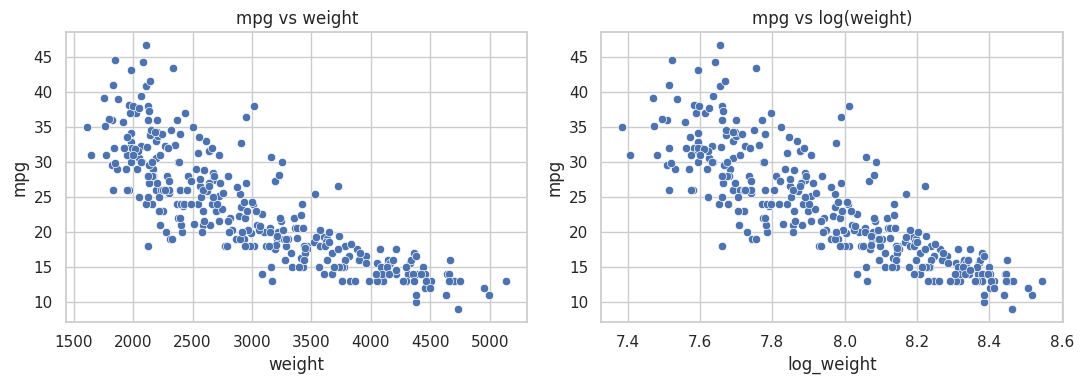

In [10]:
corr_with_y = F_train.assign(mpg=y_train).corr()['mpg'].drop('mpg').sort_values()
print('Correlation of each feature with mpg (training data):'); print(corr_with_y.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(x=X_train_raw['weight'], y=y_train, ax=ax[0]); ax[0].set_title('mpg vs weight')
sns.scatterplot(x=F_train['log_weight'], y=y_train, ax=ax[1]); ax[1].set_title('mpg vs log(weight)')
plt.tight_layout(); plt.show()

## 4. Train models
Baseline (training mean), OLS, and Ridge (penalty chosen by internal 5-fold CV over a log grid), each on the raw and engineered feature sets.

In [11]:
alphas = np.logspace(-3, 3, 50)
def make(model_name, engineered):
    fb = FeatureBuilder(engineered=engineered)
    if model_name == 'Baseline (mean)': est = DummyRegressor(strategy='mean')
    elif model_name == 'OLS':           est = LinearRegression()
    elif model_name == 'Ridge':         est = RidgeCV(alphas=alphas, cv=5)
    return Pipeline([('features', fb), ('scale', StandardScaler()), ('model', est)])

specs = [('Baseline (mean)', False), ('OLS', False), ('OLS', True), ('Ridge', False), ('Ridge', True)]
fitted = {}
for name, eng in specs:
    label = f"{name} | {'engineered' if eng else 'raw'}" if name != 'Baseline (mean)' else name
    fitted[label] = make(name, eng).fit(X_train_raw, y_train)
    print('Trained:', label)
print('\nRidge alpha chosen (raw):       ', round(fitted['Ridge | raw'].named_steps['model'].alpha_, 3))
print('Ridge alpha chosen (engineered):', round(fitted['Ridge | engineered'].named_steps['model'].alpha_, 3))

Trained: Baseline (mean)
Trained: OLS | raw
Trained: OLS | engineered


Trained: Ridge | raw


Trained: Ridge | engineered

Ridge alpha chosen (raw):        2.024
Ridge alpha chosen (engineered): 1.151


In [12]:
coef = pd.DataFrame({
    'OLS (engineered)':   fitted['OLS | engineered'].named_steps['model'].coef_,
    'Ridge (engineered)': fitted['Ridge | engineered'].named_steps['model'].coef_},
    index=fb_eng.transform(X_train_raw).columns).round(3)
print('Standardized coefficients (effect on mpg of +1 std in each feature):'); display(coef)

Standardized coefficients (effect on mpg of +1 std in each feature):


,OLS (engineered),Ridge (engineered)
cylinders,-2.135,-1.764
displacement,4.109,3.629
horsepower,2.542,2.264
weight,1.558,0.184
acceleration,-0.108,-0.105
model_year,1.543,1.523
origin_europe,0.642,0.674
origin_japan,0.478,0.534
log_weight,-9.278,-7.659
power_to_weight,-1.965,-1.783


## 5. Evaluate (RMSE primary, plus MAE and R²)
5-fold cross-validated RMSE on the training set (model selection) and final metrics on the untouched 20% test set.

In [13]:
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for label, pipe in fitted.items():
    name = label.split(' | ')[0]; eng = label.endswith('engineered')
    cv_rmse = -cross_val_score(make(name, eng), X_train_raw, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    pred = pipe.predict(X_test_raw)
    rows.append({'Model': label, 'CV RMSE (train)': cv_rmse.mean(), 'CV RMSE std': cv_rmse.std(),
                 'Test RMSE': np.sqrt(mean_squared_error(y_test, pred)),
                 'Test MAE': mean_absolute_error(y_test, pred), 'Test R²': r2_score(y_test, pred)})
results = pd.DataFrame(rows).set_index('Model').round(3)
display(results)

,CV RMSE (train),CV RMSE std,Test RMSE,Test MAE,Test R²
Model,,,,,
Baseline (mean),7.923,0.557,7.347,5.955,-0.004
OLS | raw,3.478,0.224,2.888,2.288,0.845
OLS | engineered,3.094,0.190,2.511,1.926,0.883
Ridge | raw,3.481,0.221,2.889,2.282,0.845
Ridge | engineered,3.097,0.183,2.518,1.920,0.882


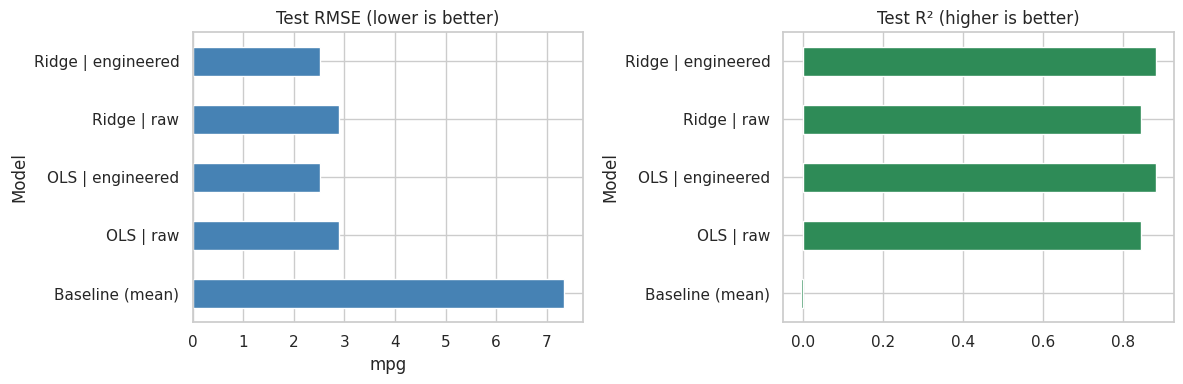

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
results['Test RMSE'].plot.barh(ax=ax[0], color='steelblue'); ax[0].set_title('Test RMSE (lower is better)'); ax[0].set_xlabel('mpg')
results['Test R²'].plot.barh(ax=ax[1], color='seagreen'); ax[1].set_title('Test R² (higher is better)')
plt.tight_layout(); plt.show()

### Diagnostics for the best linear model
Linear regression assumes residuals are centred on zero with no pattern. Curvature or a funnel shape would mean the model is missing structure.

Best model by test RMSE: OLS | engineered


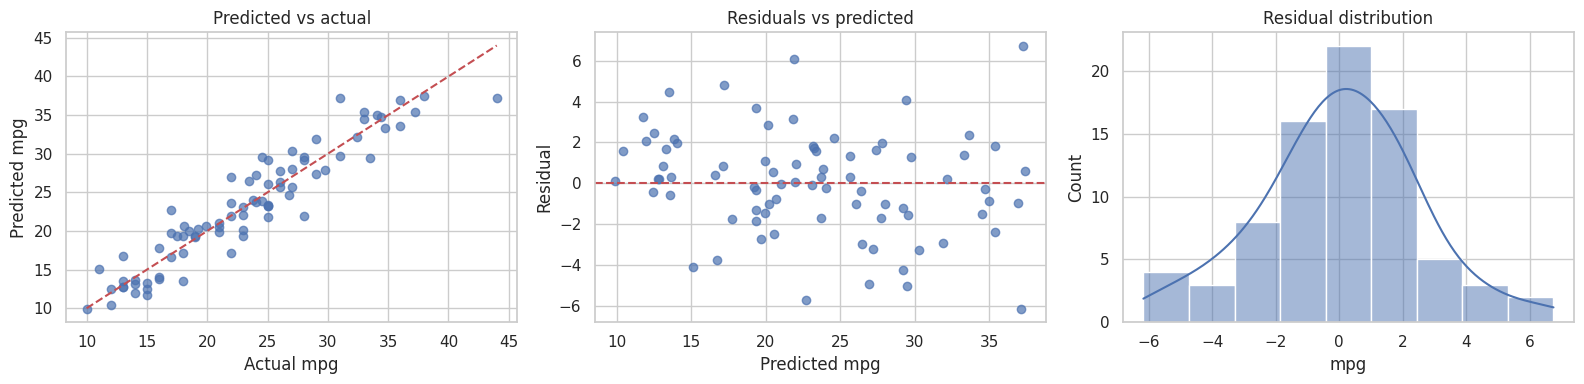

Mean residual: 0.018 | Largest absolute errors (mpg): [6.7, 6.2, 6.1]


In [15]:
best = results['Test RMSE'].drop('Baseline (mean)').idxmin()
print('Best model by test RMSE:', best)
pred = fitted[best].predict(X_test_raw); resid = y_test - pred
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(y_test, pred, alpha=.7); lims = [y_test.min(), y_test.max()]; ax[0].plot(lims, lims, 'r--'); ax[0].set_xlabel('Actual mpg'); ax[0].set_ylabel('Predicted mpg'); ax[0].set_title('Predicted vs actual')
ax[1].scatter(pred, resid, alpha=.7); ax[1].axhline(0, color='r', ls='--'); ax[1].set_xlabel('Predicted mpg'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residuals vs predicted')
sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title('Residual distribution')
plt.tight_layout(); plt.show()
print('Mean residual:', round(resid.mean(), 3), '| Largest absolute errors (mpg):', resid.abs().nlargest(3).round(1).tolist())